# Supplementary Figure 2: Associated terms

Recreate weighted term prevalence for eight packages from the sampled 2021-2025 title and abstract corpus. The helper merges listed word variants, removes structured-abstract headings, and returns the eight highest log-odds terms present in at least 2% of a package's records. See `MANUSCRIPT/02_SUPPLEMENTARY_INFO.md`, Supplementary Figures, Figure S2 caption, and `MANUSCRIPT/01_MAIN.md`, Methods, Research areas.

All figure walkthroughs use the shared Matplotlib 3.11.2 publication renderer through the bioimage-figures kernel.


In [1]:
from pathlib import Path
import sys
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import image as mpimg
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'scripts' / 'census' / '_registry.py').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate scripts/census/_registry.py from the notebook working directory')
SCRIPTS_DIR = REPO_ROOT / 'scripts'
FIGURES_DIR = SCRIPTS_DIR / 'census' / 'figures'
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import domains as dm
from census.figures import sfig2_terms as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame

## Registry and query construction

Each package's aliases join the shared microscopy context through `_registry.build_boolean_query()`. Terms are compared across analysis packages. The displayed packages follow the eight panels in the figure module.


In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'qupath', 'napari']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
2,napari,napari,"""napari"" AND ((microscopy OR microscope) AND H..."
4,qupath,QuPath,"""QuPath"" AND ((microscopy OR microscope) AND H..."


In [3]:
sample = inspect_processed('random_sample_2021_2025.csv.gz', ['tool_id', 'year', 'epmc_id', 'population', 'n_sampled', 'venue'])
d = dm.load_corpus()
print(f'Analysis corpus after registry filtering: shape={d.shape}; distinct papers={d.epmc_id.nunique():,}')
print('Weight is population divided by sampled records; census weights equal 1.')
display(d[['tool_id', 'year', 'population', 'n_sampled', 'w']].head())

random_sample_2021_2025.csv.gz: shape=(59929, 8)


,tool_id,year,epmc_id,population,n_sampled,venue
0,jupyter,2021,PPR425566,232,232,NaN
1,jupyter,2021,PPR373017,232,232,NaN
2,jupyter,2021,PPR363724,232,232,NaN
3,jupyter,2021,PPR294591,232,232,NaN
4,jupyter,2021,35127826,232,232,Frontiers in molecular biosciences


Analysis corpus after registry filtering: shape=(38487, 24); distinct papers=33,229
Weight is population divided by sampled records; census weights equal 1.


,tool_id,year,population,n_sampled,w
0,imagej,2021,36121,1000,36.121
1,imagej,2021,36121,1000,36.121
2,imagej,2021,36121,1000,36.121
3,imagej,2021,36121,1000,36.121
4,imagej,2021,36121,1000,36.121


## Term prevalence derivation

`domains.enriched_terms()` applies the project's phrase folding, stop list, 2% prevalence floor, weighted shares, and log-odds ranking. Filled-point values are the share within a package's abstracts. Open-point values are the share in all other analysis-package abstracts.


In [4]:
term_tools = figure.TOOLS
term_rows = []
for tool_id in term_tools:
    terms = dm.enriched_terms(d, tool_id, min_share=0.02, top=8).copy()
    terms.insert(0, 'tool_id', tool_id)
    term_rows.append(terms)
term_table = pd.concat(term_rows, ignore_index=True)
print(f'Term table shape: {term_table.shape}; packages: {len(term_tools)}; terms per package: 8.')
display(term_table.head(16))

selected_terms = term_table.loc[term_table.tool_id.isin(['qupath', 'napari', 'cellprofiler']),
                                 ['tool_id', 'word', 'tool_pct', 'base_pct', 'z']]
display(selected_terms)

Term table shape: (64, 5); packages: 8; terms per package: 8.


,tool_id,word,tool_pct,base_pct,z
0,imagej,western-blot,8.622377,1.386302,27.719158
1,imagej,inhibit,27.283073,14.433495,22.619435
2,imagej,apoptosis,9.012258,2.903266,20.267356
3,imagej,treatment,26.538754,16.601560,16.921238
4,imagej,ros,4.464178,1.136145,16.388220
5,imagej,assay,13.814779,7.013337,16.318727
6,imagej,suppressed,5.210390,1.688854,15.233124
7,imagej,proliferation,12.952835,6.757196,15.189072
8,imaris,brain,18.099936,9.177753,18.948514
9,imaris,synaptic,7.744595,2.622980,18.063537


,tool_id,word,tool_pct,base_pct,z
16,qupath,tumor,32.970857,13.720209,32.159906
17,qupath,immune,22.879513,9.392508,26.468456
18,qupath,patient,30.643758,15.190790,25.520211
19,qupath,cancer,30.817747,15.332714,25.491510
20,qupath,slide,4.480209,0.316900,22.434624
21,qupath,pathology,9.960853,3.005485,21.724697
22,qupath,cd8,6.676816,1.388624,21.654350
23,qupath,digital,4.654197,0.563032,21.381625
24,cellprofiler,high-content,3.310795,0.281853,18.784084
25,cellprofiler,single-cell,11.004896,4.265794,18.360541


## Optional processed-table rebuild from cached Europe PMC responses

Set `REBUILD = True` to reconstruct Europe PMC yearly counts and the microscopy denominator with the pipeline collection functions. A cache-only reader raises on missing responses, so this cell cannot fetch data. It writes comparison CSVs in a temporary folder and leaves `data/processed` unchanged. Repository-star and package-download snapshots remain the saved observations.


In [5]:
REBUILD = False
if REBUILD:
    import json
    from unittest.mock import patch
    from census import _http
    from census.sources import europepmc

    def cached_json(source, url, params=None, **kwargs):
        cache = _http._cache_path(source, url, params)
        if not cache.is_file():
            raise FileNotFoundError(f'Missing cached response: {cache.name}; no request was sent')
        return json.loads(cache.read_text())

    with patch.object(europepmc, 'get_json', cached_json):
        rebuilt_counts = pd.DataFrame(europepmc.collect_yearly(reg))
        rebuilt_corpus = pd.DataFrame(europepmc.corpus_yearly(reg))
    pd.testing.assert_frame_equal(rebuilt_counts.reset_index(drop=True), fs.europepmc_yearly().assign(source='europepmc')[rebuilt_counts.columns].reset_index(drop=True))
    pd.testing.assert_frame_equal(rebuilt_corpus, fs.load('corpus_yearly.csv'))
    with TemporaryDirectory(prefix='cached-processed-rebuild-') as output_dir:
        rebuilt_counts.to_csv(Path(output_dir) / 'literature_europepmc_yearly.csv', index=False)
        rebuilt_corpus.to_csv(Path(output_dir) / 'corpus_yearly.csv', index=False)
        print(f'Cached tables match: counts {rebuilt_counts.shape}, corpus {rebuilt_corpus.shape}')


## Render and compare

The final cell uses `style.save` for the notebook build, calls the module's `main(out_dir=...)` in a second temporary directory, compares the PNG arrays, and displays a scaled preview.


wrote SFigure2__terms.png/.pdf/.svg


wrote SFigure2__terms.png/.pdf/.svg
PNG shape: (1298, 2092, 4); mean absolute pixel difference: 0.000000


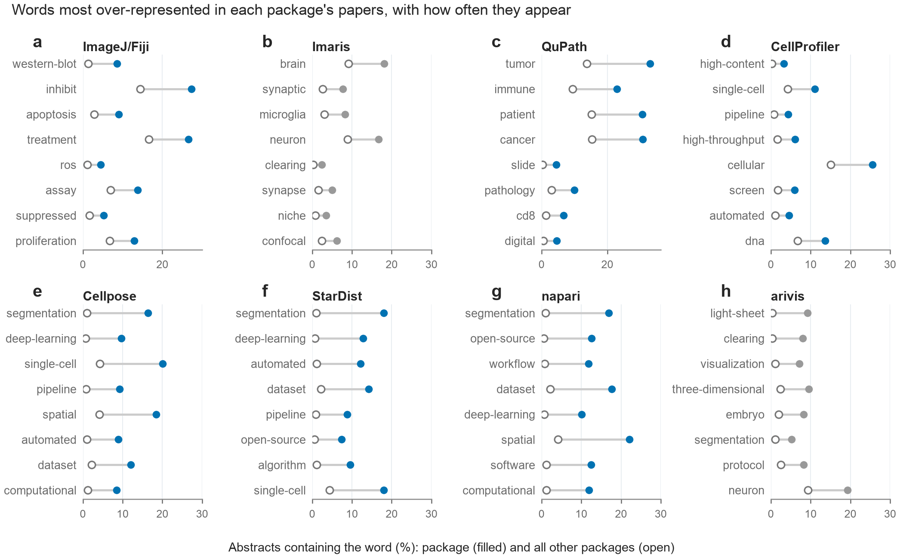

In [6]:
OUTPUT_STEM = 'SFigure2__terms'
fig = figure.build_figure()
with TemporaryDirectory(prefix='sfigure2-notebook-') as notebook_dir, TemporaryDirectory(prefix='sfigure2-module-') as module_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=notebook_dir)
    figure.main(out_dir=module_dir)
    notebook_png = Path(notebook_dir) / f'{OUTPUT_STEM}.png'
    module_png = Path(module_dir) / f'{OUTPUT_STEM}.png'
    notebook_image = mpimg.imread(notebook_png)
    module_image = mpimg.imread(module_png)
    assert notebook_image.shape == module_image.shape, (notebook_image.shape, module_image.shape)
    np.testing.assert_array_equal(notebook_image, module_image)
    print(f'PNG shape: {notebook_image.shape}; mean absolute pixel difference: {np.abs(notebook_image - module_image).mean():.6f}')
    from io import BytesIO
    from PIL import Image as PILImage
    preview = PILImage.open(notebook_png)
    preview.thumbnail((900, 900))
    preview_bytes = BytesIO()
    preview.save(preview_bytes, format='PNG')
    display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')